# Labo 5 - Pandas, Matplotlib et Jupyter Notebook

Ce laboratoire vise à apprendre à manipuler des fichiers de données avec Pandas et pratiquer votre utilisation de Matplotlib et Jupyter Notebook. Il vaut pour 10% de la note finale. La collaboration est suggérée et encouragée, mais le laboratoire doit être remis individuellement.

Tout ce vous avez besoin se trouve sur la documentation : https://pandas.pydata.org/docs/reference/frame.html.

## Explorer les fonctionnalités offertes par Matplotlib (Formatif)
Effectuer le tutoriel suivant :

* Pyplot de matplotlib : https://matplotlib.org/stable/tutorials/introductory/pyplot.html

## Analyse de données météorologiques (SOMMATIF)
Je vous fournis un ensemble de donnée météorologiques que vous allez pouvoir analyser grâce à différents graphiques. Votre soumission prendra la forme d’un rapport écrit dans un jupyter notebook (complétez les questions directement dans ce notebook). Les données météorologiques fournies représentent des informations sur la météo d’une ville dans lemonde entre le 1er juillet 1943 et le 30 août 1945. À l’origine, ce jeu de données a été utilisé pour l’analyse des conditions météorologiques durant la seconde guerre mondiale. Une version beaucoup plus complète peut-être trouvée ici.

Prenez connaissance du jeu de donné fourni. Deux fichiers au format ```.csv``` sont disponibles dans le dossier du laboratoire. Le fichier ```weather.csv``` contient les informations sur la température d’une ville, tandis que le fichier ```locations.csv``` contient des informations sur les villes qui ont été sondées lors de la collecte des données.

Pour votre information, voici le contenu des colonnes du fichier ```weather.csv```.

| Ville         | Précipitations | Temp maximale  | Temp minimale  | Temp moyenne   | Neige          | Année          | Mois           | Jour           |
| ------------- | -------------- | -------------- | -------------- | -------------- | -------------- | -------------- | -------------- | -------------- |
| xxxxx         | 12345          | 12345          | -12345         | 0              | 12345          | 1900           | Janvier        | 01             |
| ...           | ...            | ...            | ...            | ...            | ...            | ...            | ...            | ...            |

"et celui du fichier ```locations.csv```.

| Ville         | Nom            | Province/État  | Élévation      | Latitude       | Longitude      | 
| ------------- | -------------- | -------------- | -------------- | -------------- | -------------- | 
| xxxxx         | xxxxx          | xxxxx          | -12345         | 0              | 12345          |
| ...           | ...            | ...            | ...            | ...            | ...            |

Répondez aux questions directement dans le *notebook*. Des cellules codes sont disponibles à chaque question à cet effet. Lisez les commentaires dans le code pour des instructions importantes sur les étapes à suivres. Ne changez pas le nom des variables ou des fonctions si elles sont déjà écrites.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### Question 1 - Chargement des données
Prenez connaissance du jeu de données fourni. Deux fichiers au format ```.csv``` sont disponibles dans le dossier du laboratoire. Le fichier ```meteo.csv``` contient les informations sur la température d'un endroit, tandis que le fichier ```locations.csv``` contient des informations sur les endroits qui ont été sondés lors de la collecte des données.

Chargez ces données avec la fonction approppriée de Pandas. Affichez les premières lignes de chacun de ces fichiers avec la fonction head (par défaut, les 5 premières lignes sont affichées). 

In [2]:
# Chargement d'un DataFrame à partir d'un fichier csv
meteo = pd.read_csv("weather.csv") # chargez les données météo ici
locations = pd.read_csv("locations.csv") # chargez les locations ici

# Affichez vos df
meteo.head()

,ID_VILLE,PRECIPITATIONS,TEMP_MAX,TEMP_MIN,TEMP_MOY,NEIGE,ANNEE,MOIS,JOUR
0,10001,1.016,25.555556,22.222222,23.888889,0,42,7,1
1,10001,0.000,28.888889,21.666667,25.555556,0,42,7,2
2,10001,2.540,26.111111,22.222222,24.444444,0,42,7,3
3,10001,2.540,26.666667,22.222222,24.444444,0,42,7,4
4,10001,0.000,26.666667,21.666667,24.444444,0,42,7,5


In [3]:
locations.head()

,ID_VILLE,NOM,ETAT,ELEVATION,LATITUDE,LONGITUDE
0,33013,AIN EL,AL,611,36.383333,6.650000
1,33031,LA SENIA,AL,88,35.616667,0.583333
2,33023,MAISON BLANCHE,AL,23,36.716667,3.216667
3,33044,TELERGMA,AL,754,36.116667,6.416667
4,12001,TINDOUF,AL,443,27.683333,-8.083333


Remarquez l'information affichée (nombre de colonnes, nombre d'entrées...). Maintenant, affichez aussi les types des données chargées. Que remarquez-vous? 

*Votre réponse ici : Les deux dataframes contiennent des colonnes avec des types variés (int, float, str).*

In [8]:
types_meteo = meteo.dtypes
shape_meteo = meteo.shape
types_locations = locations.dtypes
shape_locations = locations.shape
print("Types de données pour les données météo:")
print(types_meteo)
print("Dimensions du DataFrame météo:")
print(shape_meteo)  
print("Types de données pour les locations:")
print(types_locations)
print("Dimensions du DataFrame locations:")
print(shape_locations)

Types de données pour les données météo:
ID_VILLE            int64
PRECIPITATIONS    float64
TEMP_MAX          float64
TEMP_MIN          float64
TEMP_MOY          float64
NEIGE               int64
ANNEE               int64
MOIS                int64
JOUR                int64
dtype: object
Dimensions du DataFrame météo:
(1156, 9)
Types de données pour les locations:
ID_VILLE       int64
NOM              str
ETAT             str
ELEVATION      int64
LATITUDE     float64
LONGITUDE    float64
dtype: object
Dimensions du DataFrame locations:
(161, 6)


### Question 2 - Dates
Créons une Series Pandas à partir des colonnes ***ANNEE***, ***MOIS*** et ***JOUR*** des données météo. Utilisez ensuite la fonction ```to_datetime()``` pour convertir les données en type "datetime". Insérez ensuite cette série comme nouvelle colonne dans le DataFrame meteo sous le nom **"Dates"**.

In [10]:
dates = meteo[["ANNEE", "MOIS", "JOUR"]] # calculez les dates ici
dates["ANNEE"] = 1900 + dates["ANNEE"] # convertir les années en années complètes
# convertissez les dates...
dates["DATE"] = pd.to_datetime(dates.rename(columns={"ANNEE": "year", "MOIS": "month", "JOUR": "day"}))
# insérez la Series comme nouvelle colonne dans le DataFrame...
meteo["DATE"] = dates["DATE"]
print(dates.head())

   ANNEE  MOIS  JOUR       DATE
0   1942     7     1 1942-07-01
1   1942     7     2 1942-07-02
2   1942     7     3 1942-07-03
3   1942     7     4 1942-07-04
4   1942     7     5 1942-07-05


### Question 3 - Indexage

Indexer les données météo avec la nouvelle colonne **Dates**. 

In [11]:
# indexer les données ici
meteo_indexe = meteo.set_index("DATE")
print(meteo_indexe.head())

            ID_VILLE  PRECIPITATIONS   TEMP_MAX   TEMP_MIN   TEMP_MOY  NEIGE  \
DATE                                                                           
1942-07-01     10001           1.016  25.555556  22.222222  23.888889      0   
1942-07-02     10001           0.000  28.888889  21.666667  25.555556      0   
1942-07-03     10001           2.540  26.111111  22.222222  24.444444      0   
1942-07-04     10001           2.540  26.666667  22.222222  24.444444      0   
1942-07-05     10001           0.000  26.666667  21.666667  24.444444      0   

            ANNEE  MOIS  JOUR  
DATE                           
1942-07-01     42     7     1  
1942-07-02     42     7     2  
1942-07-03     42     7     3  
1942-07-04     42     7     4  
1942-07-05     42     7     5  


### Question 4 - Calcul de la moyenne
Faites ressortir la température moyenne disponible dans ```weather.csv```. Il se trouve que vous avez aussi accès à la température maximale et minimale. Calculez votre propre température moyenne à partir de ces deux données. Insérez cette nouvelle série calculée comme colonne dans le DataFrame, titrée "Moyenne". Puis, faites une analyse comparative de la température moyenne fournie et de celle que vous avez vous-même calculée. Utilisez ```matplotlib``` pour en avoir une représentation visuelle. Utilisez la colonne "Dates" comme axe des x (marqueurs temporels ou "*timestamp*"), et les températures moyennes comme y, sur 2 courbes différentes (l'une avec vos températures, et l'autre avec celles qui étaient déjà là).

DATE
1942-07-01    23.888889
1942-07-02    25.277778
1942-07-03    24.166667
1942-07-04    24.444444
1942-07-05    24.166667
                ...    
1945-08-27    25.555556
1945-08-28    24.722222
1945-08-29    24.166667
1945-08-30    25.277778
1945-08-31    25.277778
Length: 1156, dtype: float64


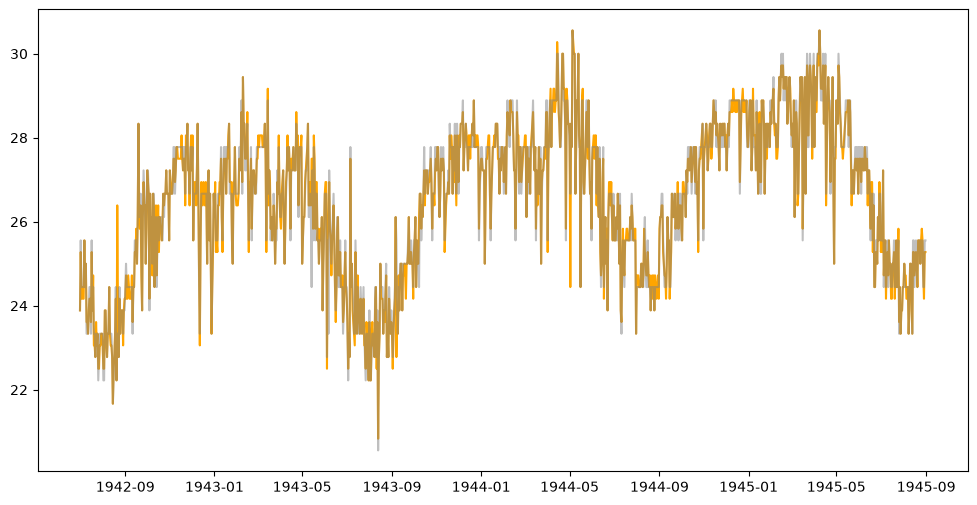

In [12]:
moyenne = (meteo_indexe["TEMP_MAX"] + meteo_indexe["TEMP_MIN"]) / 2  # calcul de la moyenne
print(moyenne)

# insertion de la colonne dans le DataFrame
meteo_indexe["Moyenne"] = moyenne

# Affichage de la moyenne des températures calculées
plt.figure(figsize=(12, 6))
plt.plot(meteo_indexe.index, meteo_indexe["Moyenne"], label="Température Moyenne calculée", color='orange')
# Ajout de la  températures moyenne fournie par le fichier CSV
plt.plot(meteo_indexe.index, meteo_indexe["TEMP_MOY"], label="Température Moyenne (CSV)", color='gray', alpha=0.5)

### Question 5 - Calcul de l'écart

À partir de votre DataFrame meteo, calculez l’écart de température entre la température maximale et minimale pour chaque entrée. Créez une nouvelle colonne « **Ecart** » dans le tableau.

In [13]:
ecart = meteo_indexe["TEMP_MAX"] - meteo_indexe["TEMP_MIN"]  # calcul de l'écart entre les températures max et min
print(ecart)

# insertion de la colonne dans le DataFrame
meteo_indexe["Ecart"] = ecart

DATE
1942-07-01    3.333333
1942-07-02    7.222222
1942-07-03    3.888889
1942-07-04    4.444444
1942-07-05    5.000000
                ...   
1945-08-27    5.555556
1945-08-28    5.000000
1945-08-29    3.888889
1945-08-30    5.000000
1945-08-31    6.111111
Length: 1156, dtype: float64


#### Partie 2 - affichez un diagramme à moustaches

À partir des données meteo, affichez un diagramme à moustaches (box plot) pour les colonnes des valeurs suivantes : températures maximales, minimales, moyennes et écart, toutes données confondues.

In [ ]:
# votre graphique ici

### Question 6 - Agrégation

À partir du DataFrame meteo, agrégez pour avoir les données par mois (ANNEE, MOIS et ID_VILLE). Les opérations d’agrégation sont : 
* le maximum des températures maximales,
* le minimum des températures minimales,
* la moyenne des température moyennes et 
* le total des précipitations.

Discartez les autres colonnes (Dates, Ecart, Moyenne).

In [ ]:
# Agregation des données par année (group by)
# indice : vous aurez besoin de changer l'index
agregat = None

#### Partie 2 - Tracez un graphique

Comparez, sur un graphique, les températures minimales de 1943, 1944 et 1945 au cours de l'année (1 courbe par année). Utilisez le minimum par année et par mois pour la valeur de température.

In [ ]:
# votre graphique ici

### Question 7 - Jointure
Propagez les données de locations aux données agrégées de météo en les liant par l'ID de la ville. La jointure doit être **inner**. Que remarquez-vous?

In [ ]:
# jointure des locations avec l'agregat
joined_df = None

### Question 8 - Sélection
Retournez le nom (**NOM**) des villes utilisées dans les données. Chaque ville doit s'y trouver seulement une fois.

Indice : la fonction ```unique()```pourrait vous servir ici.

In [ ]:
villes = None # les données africaines ici

### Question 9 - Concaténation

Ces données ne sont pas très intéressantes pour faire une analyse météo selon le lieu. Pour rendre ça plus intéressant, on va concaténer un autre ensemble de données. Cette fois-ci, prenez les données de l'Océanie (en 2 fichiers). Faites la jointure des données météo et de location de l'Océanie sur la latitude, longitude et l'élévation. Puis, concaténez celles-ci aux données agrégées et jointes précédemment (joined_df en premier).

Attention! Pour que la concaténation fonctionne, il faudra que vous ayez le même index et les mêmes colonnes. Enlevez les colonnes qui différent (ex. Continent).

In [ ]:
oceanie_meteo = None # les données de l'Océanie ici
oceanie_locations = None
oceanie = None
concat = None # la concaténation ici

#### Graphique
À partir de ces données, affichez un **histogramme (*bar plot*)** pour comparer les **températures maximales** de 5 villes en **1979** : **Wellington East** (Australie), **Melbourne** (Australie), **Isabel** (Iles Solomon), **Port Moresby** (Papouasie Nouvelle-Guinée) et **Prebbleton** (Nouvelle-Zélande).

In [ ]:
# votre graphique ici

#### Graphique 2
À partir de ces données, à l’aide d’un ***scatter plot***, affichez les **précipitations** pour l’altitude (**Elevation**) en **X** et **l’écart** en **Y**, **colorée** par la **longitude**, avec un **alpha** de **0.5**

In [ ]:
# votre graphique ici

### Question 10 - Exportation vers un fichier CSV

Finalement, exportez votre dataframe `concat` vers un fichier CSV surnommé ``result.csv``. Remettez ensuite votre notebook seulement (pas votre csv, je vais le générer avec votre fonction).

In [ ]:
def export():
# Exporter concat vers un fichier CSV
    return None

## Bonus (formatif):

Essayez de faire les questions précédentes mais en utilisant ```numpy``` cette fois. Est-ce aussi aisé? Quelles questions sont plus difficiles à faire? Quelle sont les forces de numpy? de Pandas.

## Indices

Si vous êtes bloqués, n'hésitez pas à consulter la documentation des différentes librairies utilisées.